# YAGO 4.5 KGE — notes and embedding visualizations

This notebook documents the `yago45-kge` example and visualizes the trained
**200-dimensional** entity/relation embeddings:

- **Data**: YAGO 4.5 Turtle → entity–entity triples (literals/labels dropped) →
  GestaltDB (RocksDB) ingest → CSR `SamplerSnapshot`.
- **Model**: trainable entity `[N,200]` + relation `[R,200]` tables → 2-step
  `tf_gnns.GraphNetMPNN_MLP` encoder → DistMult scorer `sum(h_s · r · h_o)`,
  InfoNCE loss over 1 positive + 8 hard negatives from `SamplerEngine`.
- **Training**: compiled `@tf.function` step; `tf.data` feed from array-backed CSR
  (no KV reads in the hot path).
- **Runs**: `data/yago45` (tiny: 352k triples / 300k entities / 57 relations,
  5k steps) and `data/yago45_facts` (8.0M triples / 3.64M entities / 27 relations,
  8k steps). Set `USE_FACTS = True` below to visualize the facts run
  (needs ~4 GB RAM for the entity matrix).


In [1]:
%matplotlib inline
import os
from pathlib import Path
import numpy as np
import polars as pl

USE_FACTS = os.environ.get("YAGO_USE_FACTS", "") == "1"  # set YAGO_USE_FACTS=1 for the 4.2M-entity run

# Works both in the workspace layout (data at repo root) and in a
# self-contained example checkout (data inside the example dir).
here = Path.cwd()
def _example_root(start):
    for p in [start, *start.parents]:
        if (p / "yago").exists() and (p / "scripts").exists():
            return p
    return start
ex = _example_root(here)
name = "yago45_facts" if USE_FACTS else "yago45"
cands = [(ex / ".." / "data" / name).resolve(), ex / "data" / name]
DATA_ROOT = next(p for p in cands if p.exists())
ART = DATA_ROOT / "artifacts"
print("DATA_ROOT:", DATA_ROOT)

DATA_ROOT: /home/charilaos/Workspace/gestalt-example/data/yago45_facts


In [2]:
import json
meta = json.loads((ART / "metadata.json").read_text())
print(f"nodes={meta['num_nodes']:,} edges={meta['num_edges']:,} relations={meta['num_relations']}")
node_map = pl.read_parquet(ART / "node_map.parquet").sort("node_int")
rel_map = pl.read_parquet(ART / "relation_map.parquet").sort("rel_int")
print(node_map.head(3))
print(rel_map)

nodes=4,181,515 edges=11,987,137 relations=25
shape: (3, 3)
┌──────────┬─────────────────────────────────┬────────┐
│ node_int ┆ node_id                         ┆ kind   │
│ ---      ┆ ---                             ┆ ---    │
│ u32      ┆ str                             ┆ str    │
╞══════════╪═════════════════════════════════╪════════╡
│ 0        ┆ yago:Second_Honeymoon__u0028_n… ┆ Entity │
│ 1        ┆ yago:Abington_Congregational_C… ┆ Entity │
│ 2        ┆ yago:Nobela                     ┆ Entity │
└──────────┴─────────────────────────────────┴────────┘
shape: (25, 3)
┌─────────┬───────────────────┬────────┐
│ rel_int ┆ edge_type         ┆ len    │
│ ---     ┆ ---               ┆ ---    │
│ u32     ┆ str               ┆ u32    │
╞═════════╪═══════════════════╪════════╡
│ 0       ┆ rdf:type          ┆ 998841 │
│ 1       ┆ schema:actor      ┆ 743804 │
│ 2       ┆ schema:alumniOf   ┆ 909793 │
│ 3       ┆ schema:author     ┆ 105631 │
│ 4       ┆ schema:award      ┆ 415083 │
│ …       ┆

## Relation distribution

Stratified sampling downstream relies on this skew (tiny is taxonomy-heavy;
facts is capped at 500k/relation for diversity).

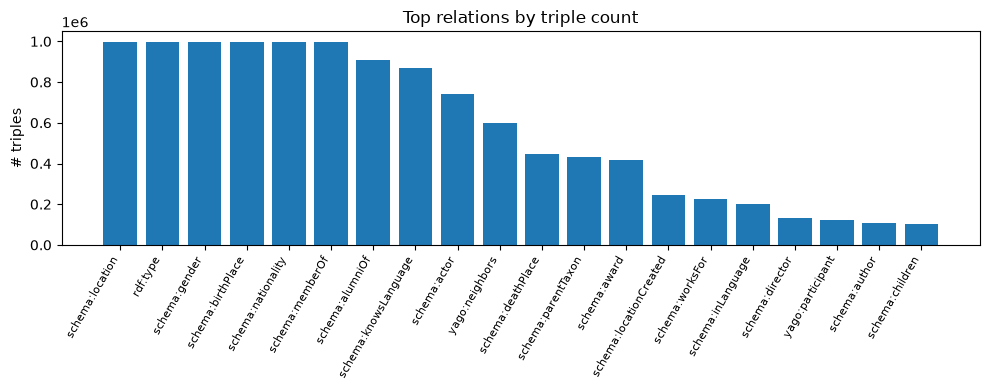

In [3]:
import matplotlib.pyplot as plt
top = rel_map.sort("len", descending=True).head(20)
names = top["edge_type"].to_list(); counts = top["len"].to_list()
plt.figure(figsize=(10, 4))
plt.bar(range(len(names)), counts)
plt.xticks(range(len(names)), names, rotation=60, ha="right", fontsize=8)
plt.ylabel("# triples"); plt.title("Top relations by triple count")
plt.tight_layout(); plt.show()

## Embedding stats and stratified subset

We sample entities stratified by their *dominant incident relation* so the
t-SNE plot tests whether the contrastive objective separated relational roles.


entity (4181515, 200) relation (25, 200)


finite: True True


entity norm: mean=0.836 std=0.269


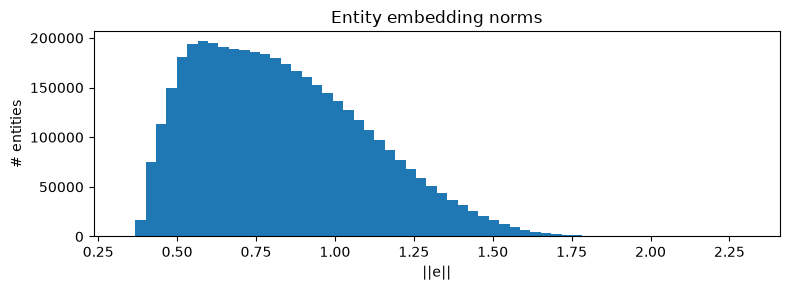

In [4]:
data = np.load(ART / "yago45_embeddings_200d.npz")
E, R = data["entity"].astype(np.float64), data["relation"].astype(np.float64)
ids = data["node_ids"].tolist()
print("entity", E.shape, "relation", R.shape)
assert E.shape[1] == 200 and R.shape[1] == 200
print("finite:", np.isfinite(E).all(), np.isfinite(R).all())
norms = np.linalg.norm(E, axis=1)
print(f"entity norm: mean={norms.mean():.3f} std={norms.std():.3f}")
plt.figure(figsize=(8, 3))
plt.hist(norms, bins=60); plt.xlabel("||e||"); plt.ylabel("# entities")
plt.title("Entity embedding norms"); plt.tight_layout(); plt.show()

In [5]:
triples = pl.scan_parquet(ART / "triples_train.parquet")
edom = (triples.group_by(["source", "edge_type"]).len()
        .sort(["source", "len"], descending=[False, True])
        .group_by("source").first()
        .collect())
print(f"entities with dominant relation: {len(edom):,}")
TOP_RELS = rel_map.sort("len", descending=True).head(8)["edge_type"].to_list()
print("plot relations:", TOP_RELS)
rng = np.random.default_rng(0)
PER_REL, sel_idx, sel_lab = 500, [], []
id_to_row = {nid: r for r, nid in enumerate(ids)}
for rel in TOP_RELS:
    cand = edom.filter(pl.col("edge_type") == rel)["source"].to_list()
    cand = [c for c in cand if c in id_to_row]
    take = rng.choice(cand, size=min(PER_REL, len(cand)), replace=False)
    sel_idx += [id_to_row[c] for c in take]; sel_lab += [rel] * len(take)
sel_idx = np.array(sel_idx); print("subset:", len(sel_idx))

entities with dominant relation: 4,032,455
plot relations: ['schema:location', 'rdf:type', 'schema:gender', 'schema:birthPlace', 'schema:nationality', 'schema:memberOf', 'schema:alumniOf', 'schema:knowsLanguage']


subset: 4000


## t-SNE of the entity subset, colored by dominant relation

t-SNE done: (4000, 2)


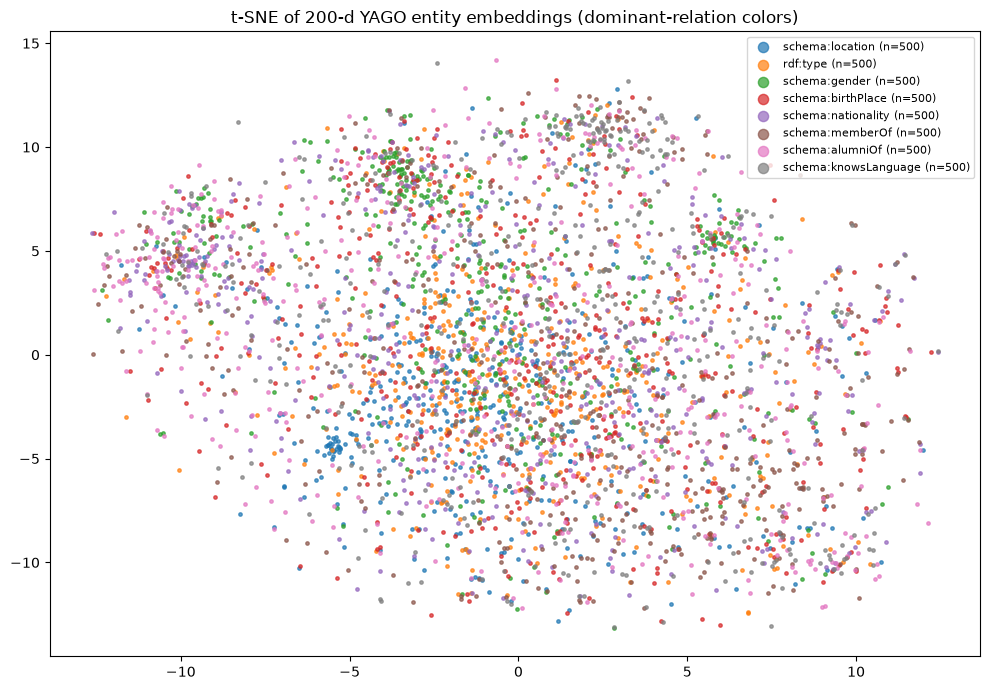

saved /home/charilaos/Workspace/gestalt-example/data/yago45_facts/artifacts/tsne_subset.png


In [6]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
Xs = StandardScaler().fit_transform(E[sel_idx])
Z = TSNE(n_components=2, perplexity=30, max_iter=1000,
         learning_rate="auto", init="pca", random_state=0).fit_transform(Xs)
print("t-SNE done:", Z.shape)
plt.figure(figsize=(10, 7))
for rel in TOP_RELS:
    m = np.array(sel_lab) == rel
    if m.sum():
        plt.scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.7, label=f"{rel} (n={m.sum()})")
plt.legend(markerscale=3, fontsize=8, loc="best")
plt.title("t-SNE of 200-d YAGO entity embeddings (dominant-relation colors)")
plt.tight_layout()
out = ART / "tsne_subset.png"; plt.savefig(out, dpi=120); plt.show()
print("saved", out)

## Train / validation curves (held-out triples)

Logged every `eval_every` steps during training. Base-table DistMult scores on
the held-out split (never in the sampler snapshot): unfiltered ranking over
1 positive + 50 random negatives. If `curves.jsonl` is missing, the run
predates validation logging.


shape: (3, 5)
┌────────┬────────────┬───────────┬──────────────┬─────────────┐
│ step   ┆ train_loss ┆ valid_mrr ┆ valid_hits10 ┆ valid_hits1 │
│ ---    ┆ ---        ┆ ---       ┆ ---          ┆ ---         │
│ i64    ┆ f64        ┆ f64       ┆ f64          ┆ f64         │
╞════════╪════════════╪═══════════╪══════════════╪═════════════╡
│ 146000 ┆ 7.575196   ┆ 0.474709  ┆ 0.635        ┆ 0.385       │
│ 148000 ┆ 7.485956   ┆ 0.474434  ┆ 0.63         ┆ 0.3875      │
│ 150000 ┆ 7.609731   ┆ 0.472594  ┆ 0.6365       ┆ 0.383       │
└────────┴────────────┴───────────┴──────────────┴─────────────┘
best valid MRR=0.4811 at step 138000


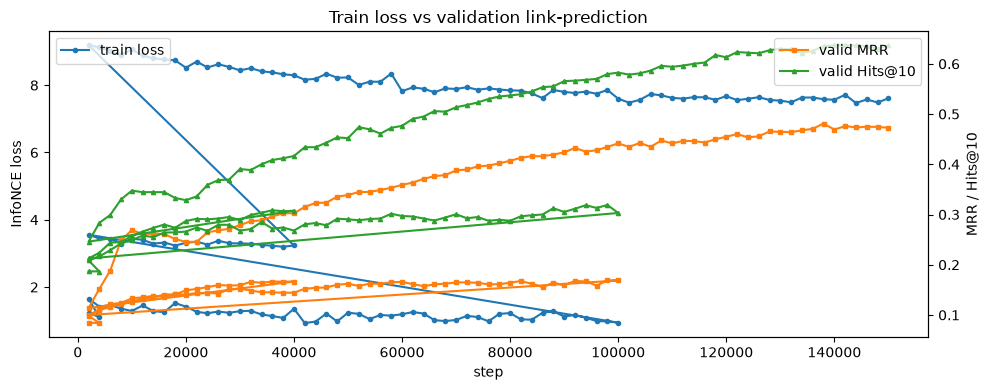

In [7]:
import json as _json
curves_file = ART / "curves.jsonl"
if curves_file.exists():
    curves = [_json.loads(l) for l in curves_file.read_text().splitlines()]
    cdf = pl.DataFrame(curves)
    print(cdf.tail(3))
    bi = int(cdf["valid_mrr"].to_numpy().argmax())
    print(f"best valid MRR={cdf['valid_mrr'][bi]:.4f} at step {int(cdf['step'][bi])}")
    fig, ax1 = plt.subplots(figsize=(10, 4))
    ax1.plot(cdf["step"].to_numpy(), cdf["train_loss"].to_numpy(), "o-", ms=3, label="train loss")
    ax1.set_xlabel("step"); ax1.set_ylabel("InfoNCE loss"); ax1.legend(loc="upper left")
    ax2 = ax1.twinx()
    ax2.plot(cdf["step"].to_numpy(), cdf["valid_mrr"].to_numpy(), "s-", ms=3, color="C1", label="valid MRR")
    ax2.plot(cdf["step"].to_numpy(), cdf["valid_hits10"].to_numpy(), "^-", ms=3, color="C2", label="valid Hits@10")
    ax2.set_ylabel("MRR / Hits@10"); ax2.legend(loc="upper right")
    plt.title("Train loss vs validation link-prediction"); plt.tight_layout(); plt.show()
else:
    print("no curves.jsonl (run predates validation logging)")

## Class-conditioned t-SNE (the right lens for ComplEx)

ComplEx geometry is per-relation (bilinear), so raw t-SNE colored by a crude
"dominant relation" proxy looks mixed even for good embeddings. Coloring by
the *true object of one relation* (gender, nationality) reveals the learned
class structure. If these plots show clean clusters, the model separated the
classes; ranking metrics (MRR/Hits) quantify it globally.


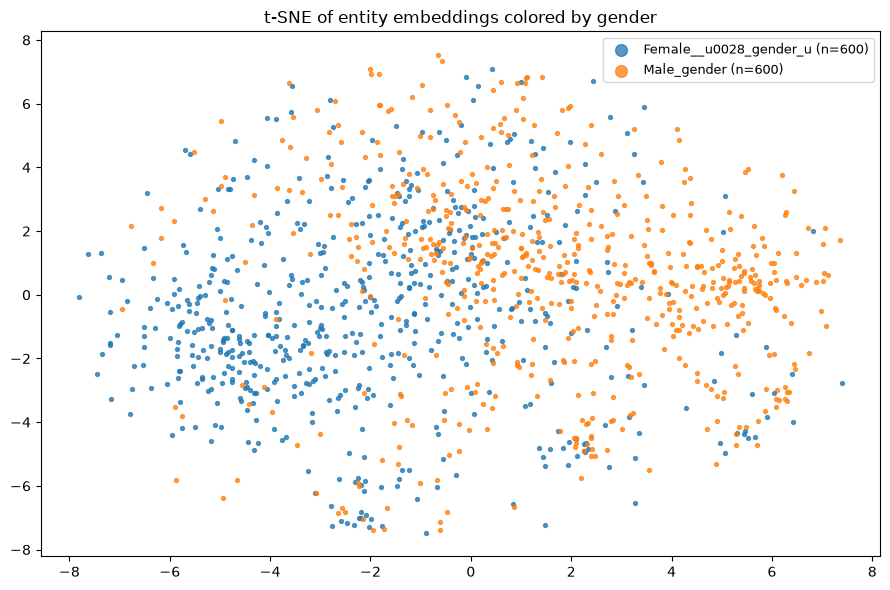

saved /home/charilaos/Workspace/gestalt-example/data/yago45_facts/artifacts/tsne_gender.png


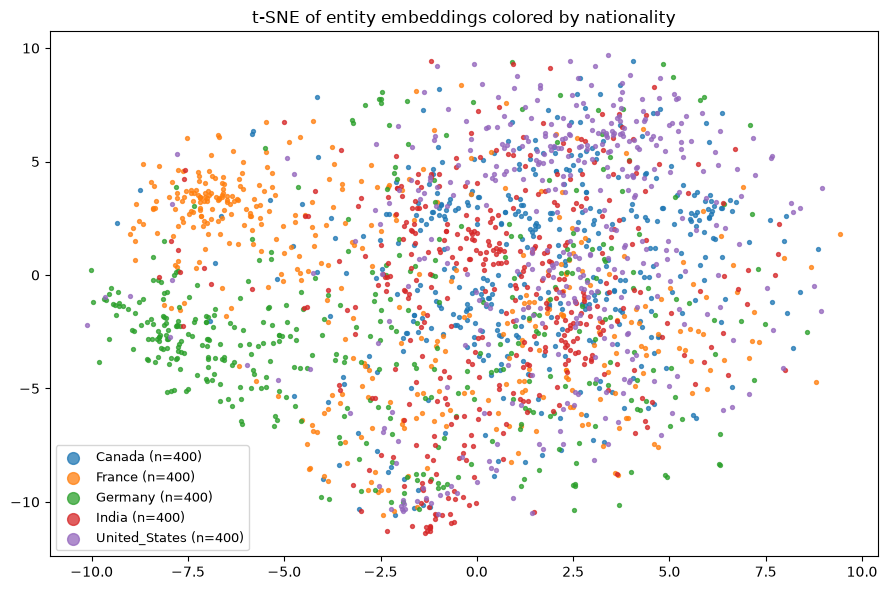

saved /home/charilaos/Workspace/gestalt-example/data/yago45_facts/artifacts/tsne_nationality.png


In [8]:
_KEEP = {
    "schema:gender": ["yago:Male_gender", "yago:Female__u0028_gender_u0029_"],
    "schema:nationality": ["yago:United_States", "yago:France", "yago:Canada", "yago:Germany", "yago:India"],
}
for _rel, _objs in _KEEP.items():
    _df = triples.filter(pl.col("edge_type") == _rel).select(["source", "target"]).collect()
    _df = _df.filter(pl.col("target").is_in(_objs))
    _rows, _labs = [], []
    for _o in _objs:
        _c = [s for s in _df.filter(pl.col("target") == _o)["source"].to_list() if s in id_to_row]
        if not _c:
            continue
        _take = list(rng.choice(_c, size=min(600 if len(_objs) <= 2 else 400, len(_c)), replace=False))
        _rows += _take; _labs += [_o.split(":")[-1][:22]] * len(_take)
    _X = StandardScaler().fit_transform(E[[id_to_row[s] for s in _rows]])
    _Z = TSNE(n_components=2, perplexity=30, max_iter=1000,
              learning_rate="auto", init="pca", random_state=0).fit_transform(_X)
    plt.figure(figsize=(9, 6))
    for _lab in sorted(set(_labs)):
        _m = np.array(_labs) == _lab
        plt.scatter(_Z[_m, 0], _Z[_m, 1], s=8, alpha=0.75, label=f"{_lab} (n={_m.sum()})")
    plt.legend(markerscale=3, fontsize=9)
    plt.title(f"t-SNE of entity embeddings colored by {_rel.split(':')[-1]}")
    plt.tight_layout()
    _fn = ART / f"tsne_{_rel.split(':')[-1]}.png"
    plt.savefig(_fn, dpi=120); plt.show()
    print("saved", _fn)

## Relation–relation cosine structure

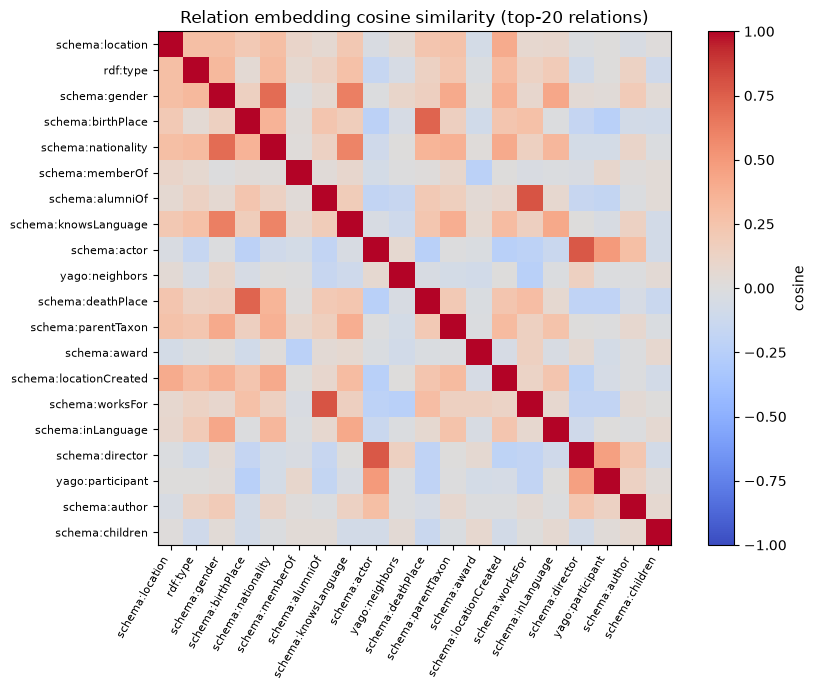

In [9]:
Rn = R / (np.linalg.norm(R, axis=1, keepdims=True) + 1e-9)
S = Rn @ Rn.T
order = np.argsort(-rel_map["len"].to_numpy())[:20]
labels = [rel_map["edge_type"][int(i)] for i in order]
plt.figure(figsize=(9, 7))
plt.imshow(S[np.ix_(order, order)], vmin=-1, vmax=1, cmap="coolwarm")
plt.xticks(range(len(labels)), labels, rotation=60, ha="right", fontsize=8)
plt.yticks(range(len(labels)), labels, fontsize=8)
plt.title("Relation embedding cosine similarity (top-20 relations)")
plt.colorbar(label="cosine"); plt.tight_layout(); plt.show()

## Nearest neighbors (spot check)

In [10]:
En = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)
def nn(name, k=5):
    i = ids.index(name)
    s = En @ En[i]; s[i] = -1
    return [(ids[j], round(float(s[j]), 4)) for j in np.argsort(-s)[:k]]
for q in [ids[i] for i in rng.choice(len(ids), size=3, replace=False)]:
    print(q)
    for nid, sc in nn(q): print(f"   {nid}  {sc}")

yago:Aye_Maung_Han


   yago:Bob_Rennie  0.5323
   yago:Aenny_Loewenstein  0.5299
   yago:Armin_Kircher  0.5248
   yago:Ashwin_Raman  0.5118
   yago:Christine_von_Brühl  0.5113
yago:Gerhold_K_u002E__Becker


   yago:Wang_Zhixing  0.582
   yago:Ludowyk_Smits  0.5779
   yago:Four_Price  0.5682
   yago:Johann_Friedrich_Mayer__u0028_agriculturist_u0029_  0.5514
   yago:Jan_Joachim_Tarło  0.5504
yago:Aulus_Sempronius_Atratinus__u0028_consul_497_BC_u0029_


   yago:David_L_u002E__Cockley  0.3958
   yago:Pipalchauri  0.3944
   yago:Parke_Wentling  0.3782
   yago:Diarsia_cia  0.3725
   yago:Antakya_minnow  0.3724


## Notes / next steps

- NN cosine values (~0.3) and relation-mixed t-SNE regions reflect a short run
  (5k/8k steps, ~6% triple coverage). More steps, larger batches, and a
  relation-aware encoder tighten clusters.
- The exported `entity` matrix is the canonical 200-d artifact (row-aligned
  with `node_ids`); the GNN refines representations *during* training, and the
  base table is what gets updated end-to-end.
- To reproduce: `bash scripts/prepare.sh [--reset-db]` then
  `bash scripts/train.sh [--steps N --batch-size B]`; see `README.md`.
